# Simulating `z2_higgs_simulation`

Trajectory simulation of the runtime, with the device's own loss, producing the runtime's four
plots. The companion to `cswap_trotter_runtime_sim.ipynb`, for the four-cavity
$\mathbb{Z}_2$-Higgs experiment rather than the two-cavity controlled swap.

The physics lives in `z2_higgs_decoherence_sim.py`, which is imported rather than repeated, so
there is exactly one implementation of the circuit and it is the one that has been checked.
This notebook is the presentation layer: it runs the study and draws the runtime's pages.

## What is fixed and what is free

**$U$ cannot be tuned on this device.** The cavities have whatever self-Kerr they have, and
Section 5 of `z2_higgs_4cavity_schemes.ipynb` is the argument that synthesising one is
expensive. **The transmon $X$ angle $g$ is free** -- it is the LOC layer's rotation, a pulse
parameter, adjustable shot to shot at no extra cost in pulses or in time.

That is enough, because the crossover depends on one dimensionless number

$$u \;=\; \frac{U}{U_c} \;=\; \frac{U\,g}{3J^2},$$

and $g$ appears in it. So the experiment is **a $g$-sweep at fixed $U$**, not a $U$-sweep.
Section 6 of the schemes notebook derives this and its one confound: in the confined sector
everything moves at the pair-hopping rate $J_{\rm pair}=J^2/2g$, so raising $g$ at fixed $Jt$
slows the dynamics and lowers $\mathcal F$ for a trivial reason. Hold the **pair-hop phase**
$\tau = J_{\rm pair}t$ fixed instead, and the trivial part is gone by construction. The
$U=0$ column is the control: if the $g$-sweep is flat there, any collapse at $U\neq0$ is real.

## What the runtime really plays

Measured on the loopback board, not assumed (`loopback_measurements/EVIDENCE.md`). One Trotter
step is three layers that take turns:

| layer | what | measured |
|---|---|---|
| LOC | transmon $X$ on all three at once | 130 ns |
| L13 | links 0 and 2 through one $W_{sym}$ train in lockstep | 1040 ns |
| L2  | link 1 alone | 1040 ns |
| | **step period** | **2210.0 ns**, model 2210.0 |

The A legs of links 0 and 2 fire together to **0.13 ns**, and each layer hands over to the next
inside 2.4 ns. Both were wrong before the board said so: L2 used to start 385 ns before L13 had
finished and swallow the next LOC rotation whole.

$W_{sym}$ is eight pulses, $B_-A_-B_+A_+B_+A_+B_-A_-$, and the sign is only a $\pi$ pump phase.
The group commutator gives $\theta = 2\epsilon^2$ per step -- verified here at
$\theta/\epsilon^2 = 1.990$ as $\epsilon\to0$, with the symmetrised train's residual ten times
smaller than a single group of four.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import z2_higgs_decoherence_sim as Z    # the circuit, the loss model and the four pages

# ---------------------------------------------------------------- the device
# Cavity T1 is per-cavity and very uneven: C3 at 80 us is twelve times worse than C1, and C3 is
# an INNER site, so loss is asymmetric about the chain and the erasure it causes is not a
# uniform background. These are the measured numbers, not a placeholder.
print("cavity T1 (us):", {f"C{i+1}": Z.T1_CAV[i] * 1e6 for i in range(4)})
print("transmon T1 (us):", {f"q{q}": Z.T1_QUBIT[q] * 1e6 for q in range(3)})
print(f"T2 (Ramsey), every mode and transmon: {Z.T2_ALL*1e6:.0f} us")

# ---------------------------------------------------------------- the operating point
G_SIDE = 2 * np.pi * 0.5e6      # rad/s, sideband coupling: a full swap in 200 ns
J = 2 * np.pi * 0.20e6           # rad/s, the hopping the W_sym train synthesises
U = 2 * np.pi * 0.05e6           # rad/s, the FIXED self-Kerr -- measure it, do not assume it
LOC_TIME = 150e-9                # s, the LOC pulse: its length, not its Trotter angle
DT = 0.05e-6                     # s, Trotter step
STEPS = list(range(0, 11))       # how many steps each point runs

# Trajectories. Every observable here is diagonal in photon number, which is the case
# trajectory averaging converges fastest on; 100 is enough to see the curves separate and
# cheap enough to re-run. Raise it for a figure.
NTRAJ = 100
# Basis cutoff. NOT the photon number: Gauss' law puts each transmon in an X eigenstate, so a
# sideband can hand up to three extra photons back to the cavities. N+2 is converged to the
# fourth decimal, N+3 cannot clip at all.
N_CUT = None                     # None -> N+3

print(f"\ng/J is the knob. U/J = {U/J:.3f} is fixed by the hardware.")

cavity T1 (us): {'C1': 900.0, 'C2': 130.0, 'C3': 80.0, 'C4': 330.0}
transmon T1 (us): {'q0': 200.0, 'q1': 200.0, 'q2': 200.0}
T2 (Ramsey), every mode and transmon: 150 us

g/J is the knob. U/J = 0.250 is fixed by the hardware.


## Operators, and what one step costs

`step_operators` returns the step as time-ordered `(H, duration)` segments in the same order the
board plays them: LOC, then L13, then L2. The LOC segment carries the rotation $\exp(-iH_{\rm
loc}\,\mathrm{d}t)$ but is stretched onto its **physical** 150 ns, because decoherence acts for
as long as the pulse really takes, not for $\mathrm{d}t$.

In [2]:
GJ = 8.0                                   # the standard operating point, g/J
g = GJ * J
occ = Z.STUDY["probe"]
N = sum(occ)
lat = Z.Lattice(n_cut=N + 3)
segs, eps = Z.step_operators(lat, g, J, U, DT, G_SIDE, loc_time=LOC_TIME)
t_step = sum(t for _H, t in segs)

print(f"probe |{''.join(map(str, occ))}>   N = {N} photons   Hilbert space {lat.D}")
print(f"eps = {eps:.4f} rad per sideband pulse   ->  theta = 2 eps^2 = {2*eps**2:.4f} = J dt")
print(f"one step: {len(segs)} segments, {t_step*1e9:.0f} ns physical")
print(f"{max(STEPS)} steps = {t_step*max(STEPS)*1e6:.1f} us, against C3's T1 of "
      f"{Z.T1_CAV[2]*1e6:.0f} us")

# Which conserved quantity each segment obeys -- the LOC layer conserves cavity photons, every
# sideband conserves cavity photons PLUS transmon excitations, and mixing the two up silently
# deletes the sideband coupling. The propagators check it rather than trusting it.
props = Z.build_propagators(lat, segs)
print("\ngrading per segment:", [p.grading for p in props[:3]], "...",
      sorted({p.grading for p in props}))

probe |1111>   N = 4 photons   Hilbert space 2640
eps = 0.1772 rad per sideband pulse   ->  theta = 2 eps^2 = 0.0628 = J dt
one step: 17 segments, 1053 ns physical
10 steps = 10.5 us, against C3's T1 of 80 us

grading per segment: ['cavity', 'excitation', 'excitation'] ... ['cavity', 'excitation']


## Running it

Three curves per observable, and keeping them apart is the point:

* **ideal** &mdash; $e^{-iHt}$, no Trotterization and no loss: the answer the experiment is for.
* **trotter** &mdash; the $W_{sym}$ sideband circuit, lossless: what Trotterization alone costs.
* **lossy** &mdash; the same circuit with the device's collapse operators.

Only the first gap is something more steps can fix.

**Why four photons and not eight.** The schemes notebook's probe and control are
$|2,2,2,2\rangle$ and $|3,1,1,3\rangle$, eight photons. Gauss' law puts each transmon in an $X$
eigenstate and a sideband can hand three of those excitations back to the cavities, so the
basis has to be cut at $N+3=11$: that is a 10920-dimensional space and 68 propagators per
point, which is not a notebook. The pair used here, $|1,1,1,1\rangle$ against
$|2,0,0,2\rangle$, is the same comparison at four photons -- same total, one flat and one
already piled two-and-two on the ends -- in 2640 dimensions. Run the eight-photon pair from
`z2_higgs_decoherence_sim.py` directly, overnight, when it is a figure rather than a check.

**How long this takes.** Minutes, not hours -- but only because the linear algebra is pinned to
ONE BLAS thread. Every matrix here is a photon-sector block a few hundred square, and OpenBLAS's
threads cost far more than they save on those: `eigh(175)` is 0.040 s on one thread and 4.218 s
on eight, a hundredfold the wrong way. `z2_higgs_decoherence_sim.one_blas_thread()` caps it, and
the parallelism is taken over trajectories instead, where it actually pays. Building the 17
segment propagators went from 44 s to 1 s that way. If this cell ever starts taking an hour,
that is the first thing to check.


In [3]:
t0 = time.time()
runs = {}
for name in ("probe", "control"):
    occ = Z.STUDY[name]
    _lat, r, _N = Z.run_study(occ, STEPS, g, J, U, DT, G_SIDE, LOC_TIME, NTRAJ,
                              n_cut=N_CUT, seed=1)
    runs[name] = r
print(f"[{time.time()-t0:.0f}s]")

  |1111>  N=4  dim=2640  eps=0.1772 rad  physical step 1053 ns  total 10.5 us


      17 propagators in 212s (excitation grading, 11 blocks); 100 trajectories
      100 trajectories on 8 workers in 920s


  |2002>  N=4  dim=2640  eps=0.1772 rad  physical step 1053 ns  total 10.5 us


      17 propagators in 116s (excitation grading, 11 blocks); 100 trajectories
      100 trajectories on 8 workers in 913s


[4081s]


## 1 bunching order parameter

$\mathcal F = \langle\mathrm{Var}(n_i)\rangle_i$ against Trotter step. A Fock preparation
starts at $\mathcal F=0$ whatever it is, so $\mathcal F$ is **made by the dynamics**, not
loaded. Left every shot, middle post-selected on the total, right what post-selection threw
away &mdash; the erasure the uneven cavity $T_1$ costs.

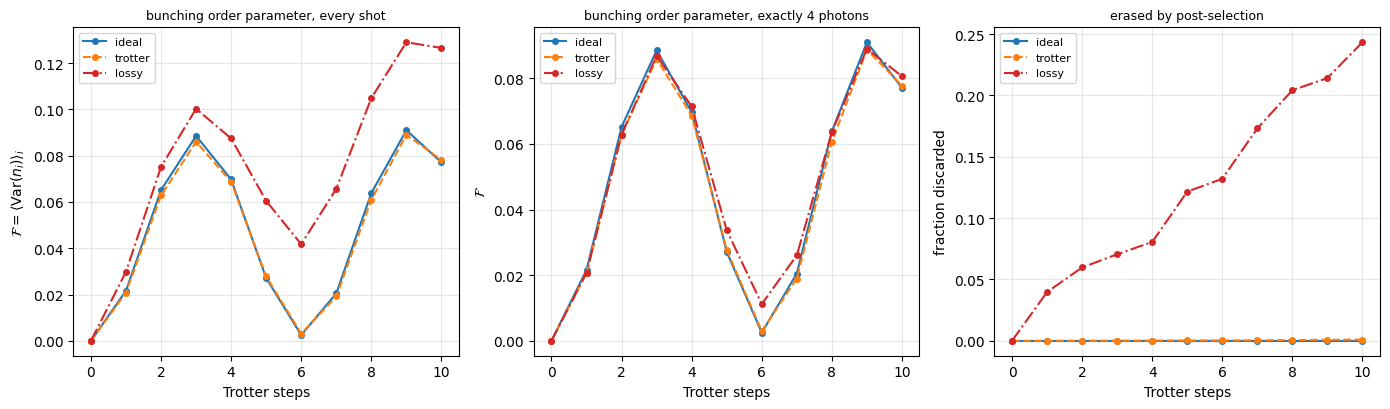

In [4]:
Z.plot_order_parameter(STEPS, runs["probe"], sum(Z.STUDY["probe"]))

## 2 site occupations and variances

Per-cavity $\langle n_i\rangle$ and $\mathrm{Var}(n_i)$. Watch C3: it has the worst $T_1$
(80 us) and is an inner site, so it is where the lossy curve leaves the others first.

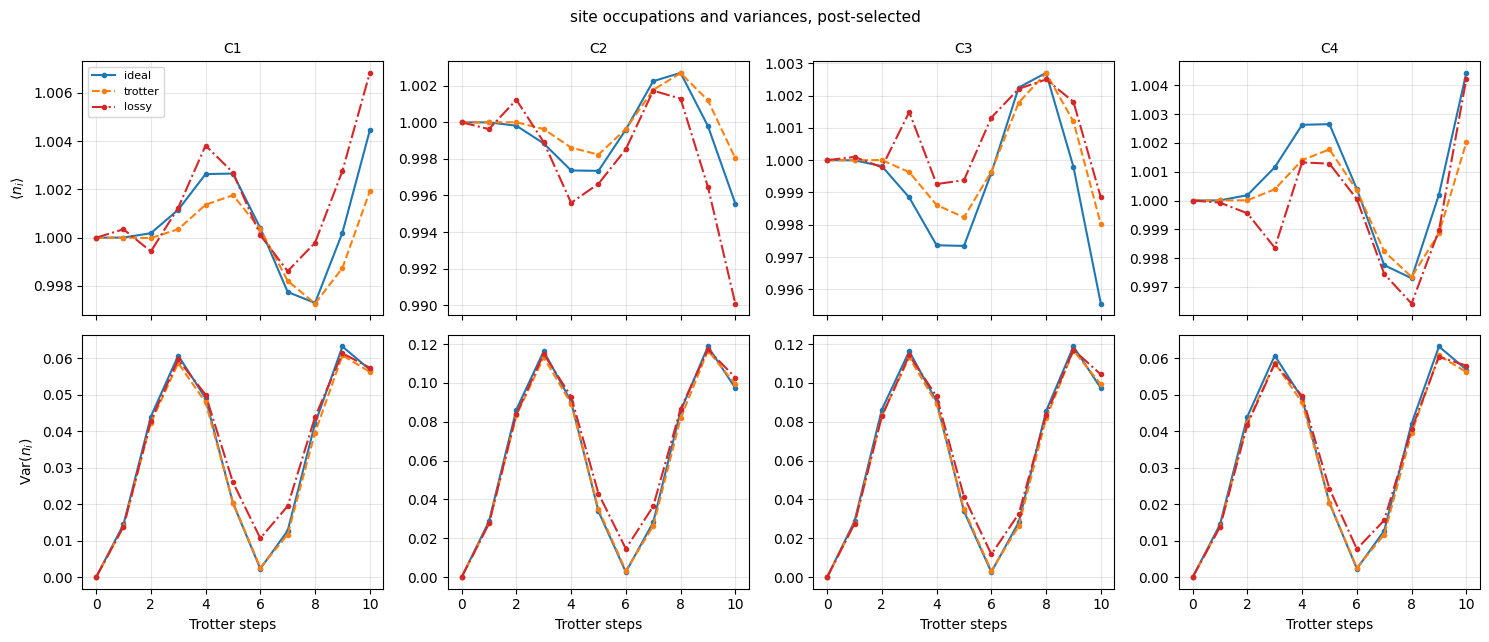

In [5]:
Z.plot_sites(STEPS, runs["probe"])

## 3 full counting statistics

$P(n_i = k)$ per cavity against Trotter step, post-selected. This is what a variance summarises,
and the tail moves well before $\mathcal F$ does. Even and odd $k$ are drawn differently
because the transmon is locked to the **parity** of the photons it moved, so confusing the two
hides real structure.

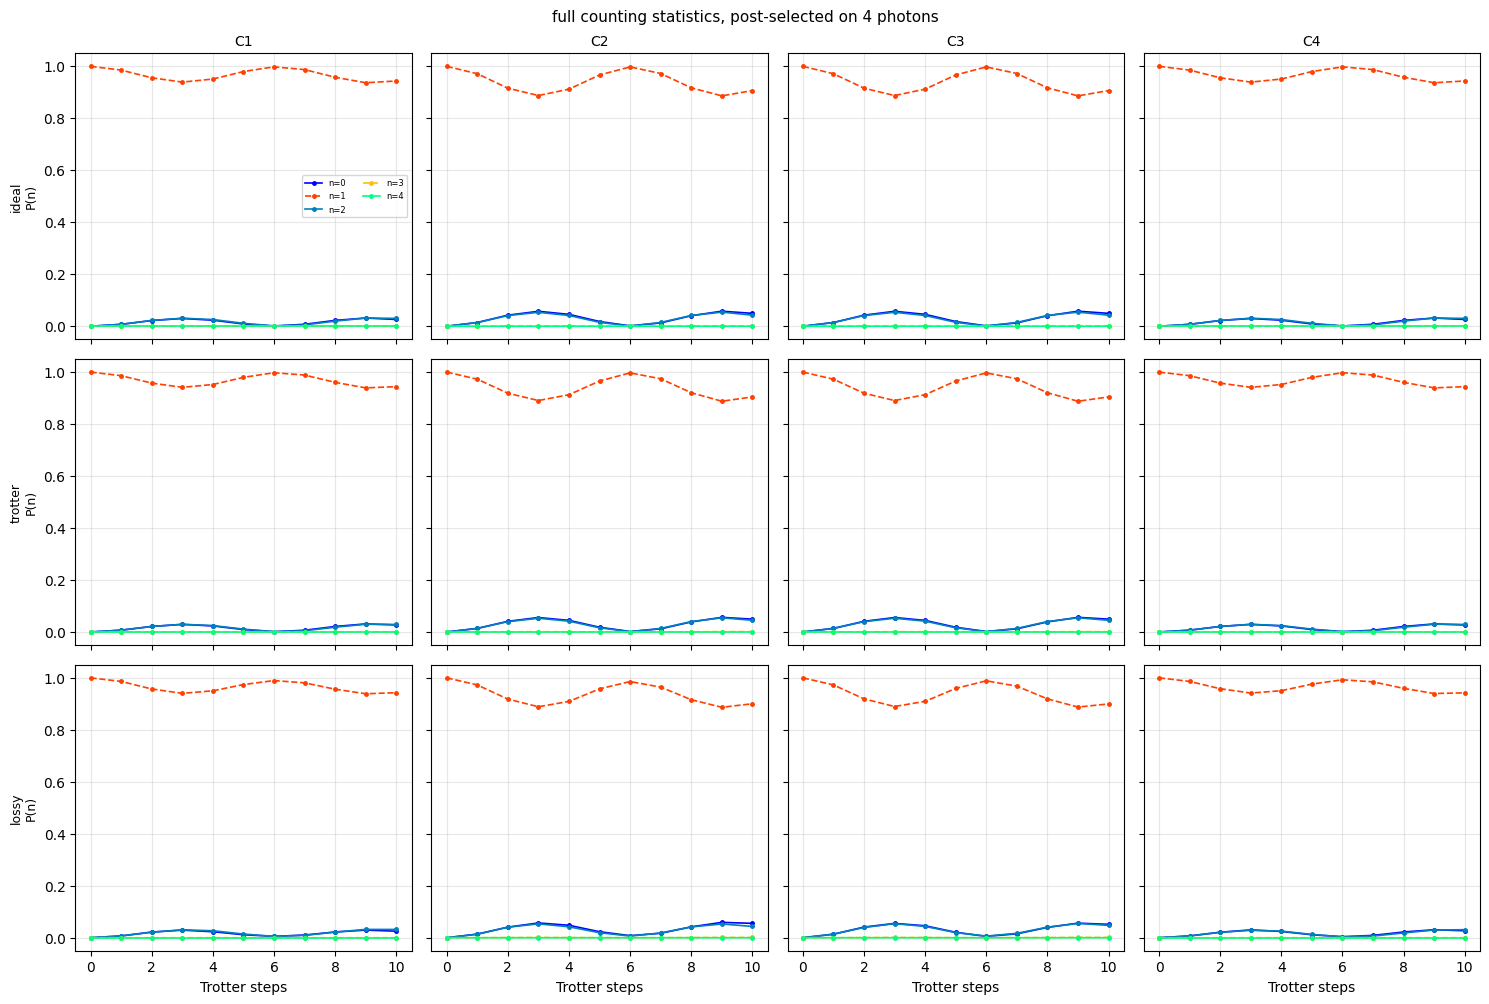

In [6]:
Z.plot_fcs(STEPS, runs["probe"], sum(Z.STUDY["probe"]))

## 4 correlations and concentration

Nearest-neighbour number correlation on each bond &mdash; the pair-hopping term is what moves it
&mdash; and the participation ratio, which is 1 when one site holds everything and 1/4 when they
are spread evenly. The IPR needs no variance and is bounded, so it does not blow up when a step
loses contrast.

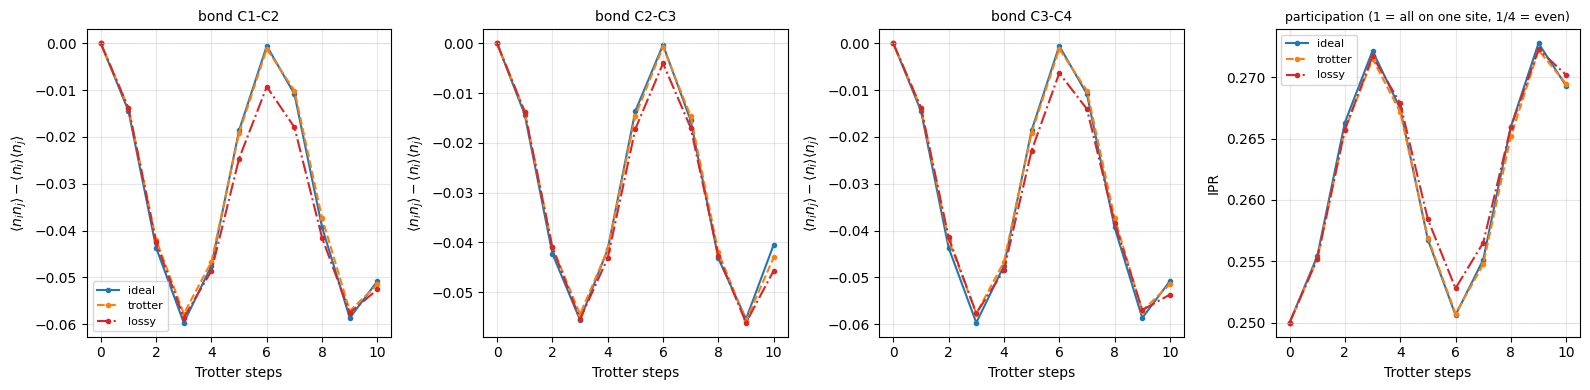

In [7]:
Z.plot_correlations(STEPS, runs["probe"])

## 5 The experiment: sweep the $X$ strength, not $U$

$U$ is frozen at the hardware's value and $g$ is swept, holding the pair-hop phase
$\tau=J^2t/2g$ fixed so the sweep is not just "slower dynamics". Two things have to be true
before any collapse means anything:

1. the $U=0$ column is **flat** &mdash; that is the control, and it is what says the $g$-sweep
   on its own does nothing;
2. the probe collapses and the control state does not, at the same $g$.

The cost is on the right: holding $\tau$ fixed means running longer at larger $g$, and the
cavity $T_1$ sets how far that can go before erasure eats the shot.

The $U=0$ control is not automatically flat, and checking it is the whole point of running it.
It is only flat once $\tau$ is large enough that the dynamics dominates the **static** $(J/g)^2$
admixture that confinement leaves in the state -- see the scan in the cell below. At the
operating point's own $\tau$ the control slopes by more than the signal does, which would have
made the sweep a measurement of $1/g^2$.


In [ ]:
t0 = time.time()
# The sweep uses the EXACT evolution, not the circuit. Holding the pair-hop phase fixed means
# running longer at larger g, and if that is done by changing the STEP COUNT then the Trotter
# error changes along the sweep too -- which lands in the answer as if it were physics. Doing it
# exactly separates the two: pages 1-4 above already show what the circuit costs at the
# operating point, and this cell is about whether the g-sweep sees the crossover at all.
#
# tau = J_pair t = J^2 t / 2g is the quantity held fixed, so t = 2 g tau / J^2.
GS = [4.0, 6.0, 8.0, 12.0, 16.0]
# tau has to be big enough that the DYNAMICS dominates, and that is not automatic. At small tau
# the order parameter is dominated by a STATIC effect instead: the confined state carries a
# virtual admixture of the singly-hopped state with amplitude ~J/g, which contributes F ~ (J/g)^2
# with no time dependence at all. Holding tau fixed does nothing about that term, so the control
# comes out steeply sloped and the sweep is measuring 1/g^2. Scanned at U=0, N=4, exact
# evolution, over g/J = 4..16:
#
#     tau      F(g/J=4)   F(g/J=8)   F(g/J=16)   spread
#     0.0196    0.1233     0.0261     0.0108     11.5x     <- static 1/g^2 term wins
#     0.0500    0.2850     0.0172     0.0184     16.6x
#     0.1250    0.2886     0.0943     0.0807      3.6x
#     0.2500    0.1845     0.2287     0.1887      1.2x     <- flat: the dynamics wins
#     0.5000    0.2490     0.1811     0.1626      1.5x     <- and it gets worse again
#
# 0.25 is an optimum, not just "as large as possible": by 0.5 the sweep has curved back.
# so 0.25 it is. The first row is what the operating point above would have given
# (5 steps x 50 ns), which is why this cell does NOT inherit tau from it.
TAU = 0.25

N = sum(Z.STUDY["probe"])
lat_s = Z.Lattice(n_cut=N + 3)
psi_s = lat_s.gauss_state(Z.STUDY["probe"])
psi_c = lat_s.gauss_state(Z.STUDY["control"])

def F_exact(state, gj, Uval):
    """The order parameter under exp(-iHt), at the time that holds tau fixed."""
    g_i = gj * J
    t_i = 2 * g_i * TAU / J ** 2
    v = Z.run_ideal(lat_s, state, lat_s.H(g_i, J, Uval), [t_i])[0]
    return Z.observables(lat_s, Z.populations(lat_s, v), N)["ps_F_bunch"], t_i

F0 = [F_exact(psi_s, gj, 0.0)[0] for gj in GS]          # U = 0: the control
F1 = [F_exact(psi_s, gj, U)[0] for gj in GS]            # U fixed by hardware: the measurement
Fc = [F_exact(psi_c, gj, U)[0] for gj in GS]            # the control STATE, same U
times = [F_exact(psi_s, gj, 0.0)[1] for gj in GS]
print(f"[{time.time()-t0:.0f}s]  tau = {TAU:.4f} rad held fixed")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for y, lab, c, m in ((F0, "$U=0$ (control: nothing to see)", "k", "o"),
                     (F1, "$U$ fixed by hardware", "tab:red", "s"),
                     (Fc, "control STATE $|2,0,0,2\\rangle$, same $U$", "tab:blue", "v")):
    ax[0].plot(GS, y, m + "-", color=c, ms=5, label=lab)
ax[0].set(xscale="log", xlabel="$g/J$   (the transmon $X$ angle: free)",
          ylabel=r"$\mathcal{F}$ at fixed pair-hop phase $\tau$",
          title="sweep $g$, not $U$", ylim=(0, None))
ax[0].grid(True, alpha=0.3); ax[0].legend(fontsize=7)

ax[1].plot(GS, [t * 1e6 for t in times], "ko-", ms=5)
ax[1].axhline(Z.T1_CAV[2] * 1e6 / N, color="tab:red", ls="--",
              label=r"$T_1^{C3}/N$: where the first photon goes")
ax[1].set(xscale="log", yscale="log", xlabel="$g/J$", ylabel="evolution time ($\\mu$s)",
          title="what holding $\\tau$ fixed costs")
ax[1].grid(True, alpha=0.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

span = lambda y: max(y) / max(min(y), 1e-12)
print(f"U = 0      : F varies {span(F0):5.2f}x over g/J = {GS[0]:.0f}..{GS[-1]:.0f}"
      "   <- THE CONTROL. If this is not flat, stop: the sweep is measuring its own confound.")
print(f"U fixed    : F varies {span(F1):5.2f}x   <- the measurement")
print(f"probe/control contrast at g/J={GS[-1]:.0f}: {F1[-1]/max(Fc[-1], 1e-12):5.2f}x")


## What to run, in order

1. **Phase calibration** (`z2_higgs_phase_calibration`). Every sideband against every
   interleaved sideband, plus the idle drift, written into `pulses_extra`. Nothing below is
   meaningful until the frames are tracked: the train assumes the slopes it is handed.
2. **Counting fidelity, no dynamics.** Prepare each of the four Fock states, run **zero**
   Trotter steps, count. This measures the counting itself: the post-selected fraction at
   $n=0$ is the erasure floor every later point is divided by, and it is not 1.
3. **The probe at the standard operating point**, $g/J=8$, steps $0\ldots N$. That is page 1
   above. $\mathcal F$ must grow from 0 and the erasure must stay well under the kept fraction.
4. **The control state** ($|2,0,0,2\rangle$ here, $|3,1,1,3\rangle$ at eight photons), identical settings. Same total, different
   arrangement; the pair that separates is the measurement.
5. **The $g$-sweep**, holding $\tau$ fixed, with the $U=0$ column run first. If the control is
   not flat, stop -- the sweep is measuring its own confound, not the crossover.

Post-selection is on the **total** photon number, which the ideal dynamics conserves exactly:
the electric term is diagonal in it and the hopping moves photons between cavities without
creating or destroying them. A shot with a different total lost a photon, and the erased
fraction on page 1 is how often.